# 01 · Os dados: seis edições do State of Data Brazil

**Pergunta do projeto:** quanto ganha quem trabalha com dados no Brasil, e
do que isso depende.

**Fonte:** State of Data Brazil, pesquisa anual da comunidade Data Hackers
com a Bain & Company, publicada no Kaggle pela conta `datahackers`. Licença
**CC BY-NC-SA 4.0**: uso não comercial, com atribuição, e o que for
derivado sai na mesma licença.

Este caderno mostra de onde vêm os dados, como as seis edições viram uma
tabela só e **quem responde a pesquisa** — o limite de tudo o que vem depois.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from salarios import harmonizar as h
from salarios.edicoes import EDICOES
from salarios.graficos import estilo, AZUL, LARANJA, VERDE, TINTA_2

estilo()
pd.set_option("display.max_columns", 30)
df = pd.read_parquet("../dados/tratados/respostas.parquet")
df.shape

(22686, 24)

## As edições

Coleta online, de meados de outubro a meados de dezembro de cada ano (a
edição de 2019 não informa o período). Não houve edição de 2020.

In [2]:
edicoes = (df.groupby("ano")
             .agg(respostas=("resposta", "size"),
                  com_salario=("sal_min", lambda s: s.notna().sum()))
             .assign(perguntas_harmonizadas=[len(EDICOES[a]["colunas"]) for a in EDICOES]))
edicoes

,respostas,com_salario,perguntas_harmonizadas
ano,,,
2019,1765,1527,14
2021,2645,2365,19
2022,4271,3694,19
2023,5293,4753,19
2024,5217,4863,19
2025,3495,3227,19


## Harmonização

O questionário muda todo ano: letras das perguntas, nomes das opções,
agrupamento de cargos e faixas de experiência. A harmonização
(`salarios/harmonizar.py`) segue três regras:

1. **A coluna é escolhida pelo texto da pergunta, não pela letra.** A
   pergunta "Atualmente qual a sua forma de trabalho?" é P2_q em 2021, P2_p
   em 2022, P2_r em 2023, 2.r em 2024 e 2.q em 2025.
2. **Todo valor bruto passa por um mapa explícito.** Valor que nenhum mapa
   conhece interrompe a carga em vez de virar vazio.
3. **O que é ambíguo vira vazio, e está escrito por quê.**

Os casos que o dado trouxe:

In [3]:
pd.DataFrame([
    ("Faixa 'de R$ 101 a R$ 2.000' (2023, 1 resposta)", "R$ 1.001 a R$ 2.000", "o teto bate com essa faixa; falta um dígito no piso"),
    ("Faixa 'de R$ 25.001 a R$ 3000' (2025, 1 resposta)", "vazio", "pode ser 25–30 mil ou 2–3 mil"),
    ("Porte 'de 501 a 100' (2023 e 2025, 2 respostas)", "vazio", "501–1.000 ou 51–100?"),
    ("Gestores de 2019 que também deram o cargo (29)", "cargo mantido, família 'Gestor'", "de 2021 em diante gestor não responde cargo"),
    ("'Especialista/Staff+' (só 2025)", "nível próprio + 'Sênior' no comparável", "antes de 2025 essas pessoas marcavam Sênior"),
    ("BI e Analytics Engineer (juntos em 2021)", "família 'Analista de BI / Analytics Engineer'", "comparar anos exige a família mais larga"),
    ("Engenheiro e arquiteto de dados (juntos em 2022–23)", "família 'Engenheiro / Arquiteto de Dados'", "idem"),
], columns=["caso", "decisão", "por quê"])

,caso,decisão,por quê
0,"Faixa 'de R$ 101 a R$ 2.000' (2023, 1 resposta)",R$ 1.001 a R$ 2.000,o teto bate com essa faixa; falta um dígito no...
1,"Faixa 'de R$ 25.001 a R$ 3000' (2025, 1 resposta)",vazio,pode ser 25–30 mil ou 2–3 mil
2,"Porte 'de 501 a 100' (2023 e 2025, 2 respostas)",vazio,501–1.000 ou 51–100?
3,Gestores de 2019 que também deram o cargo (29),"cargo mantido, família 'Gestor'",de 2021 em diante gestor não responde cargo
4,'Especialista/Staff+' (só 2025),nível próprio + 'Sênior' no comparável,antes de 2025 essas pessoas marcavam Sênior
5,BI e Analytics Engineer (juntos em 2021),família 'Analista de BI / Analytics Engineer',comparar anos exige a família mais larga
6,Engenheiro e arquiteto de dados (juntos em 202...,família 'Engenheiro / Arquiteto de Dados',idem


Os 19 testes em `tests/` conferem a tabela contra os CSVs brutos: nenhuma
resposta some, só vira vazio o que o mapa manda esvaziar, as faixas de cada
ano encostam uma na outra sem buraco. Cada teste foi sabotado uma vez para
provar que pega o defeito que promete pegar.

## As faixas de salário

A pesquisa não pergunta o salário, pergunta a faixa. Cada resposta vira um
intervalo `[sal_min, sal_max]`; a faixa do topo é aberta.

In [4]:
faixas = (df.dropna(subset=["sal_min"])
            .groupby("ano")
            .agg(faixas=("faixa", "nunique"),
                 topo_aberto_a_partir_de=("sal_min", "max"),
                 no_topo_aberto=("sal_max", lambda s: f"{np.isinf(s).mean():.1%}")))
faixas

,faixas,topo_aberto_a_partir_de,no_topo_aberto
ano,,,
2019,11,25001.0,0.9%
2021,13,40001.0,1.4%
2022,13,40001.0,1.2%
2023,14,40001.0,1.5%
2024,13,40001.0,2.1%
2025,13,40001.0,3.6%


O topo aberto muda de R$ 25.001 (2019) para R$ 40.001 (2021 em diante). Em
2025, 3,6% das respostas estão nele, mais que o dobro dos 1,5% de 2023 — a parte de cima da
distribuição está ficando mais cheia, e é onde a faixa diz menos. Para comparar 2019 com os outros anos,
a análise de evolução usa um topo comum de R$ 25.001.

## Quem responde

A pesquisa é online e divulgada na comunidade Data Hackers: **a amostra é
autosselecionada**. Ela descreve quem responde, não o mercado inteiro. Os
números abaixo servem para saber quanto pesa cada grupo — e onde a amostra é
pequena demais para afirmar alguma coisa.

In [5]:
no_brasil = df[df["situacao"] != "Fora do Brasil"]
composicao = pd.crosstab(no_brasil["familia"], no_brasil["ano"], normalize="columns").mul(100).round(1)
composicao.loc[composicao.max(axis=1).sort_values(ascending=False).index]

ano,2019,2021,2022,2023,2024,2025
familia,,,,,,
Gestor,20.0,21.6,19.4,18.8,21.4,22.5
Analista de Dados,10.5,13.6,17.3,19.2,19.8,18.6
Outros,17.6,9.1,11.9,8.4,7.9,9.4
Cientista de Dados,10.9,15.1,15.0,14.4,14.2,13.3
Analista de BI / Analytics Engineer,9.5,14.4,12.2,13.6,12.9,10.9
Desenvolvedor / Eng. de Software,14.4,4.4,2.9,2.2,2.5,3.2
Engenheiro / Arquiteto de Dados,8.3,12.9,13.1,14.3,13.4,13.2
Analista de Negócios,4.5,4.1,3.3,4.1,3.8,4.4
Engenheiro de ML,1.0,2.1,1.8,1.6,2.1,3.3


In [6]:
perfil = pd.DataFrame({
    "mulheres (%)": no_brasil.groupby("ano")["genero"].apply(lambda s: (s == "Feminino").mean() * 100),
    "Sudeste (%)": no_brasil.groupby("ano")["regiao"].apply(lambda s: (s == "Sudeste").mean() * 100),
    "São Paulo (%)": no_brasil.groupby("ano")["uf"].apply(lambda s: (s == "SP").mean() * 100),
    "pós, mestrado ou doutorado (%)": no_brasil.groupby("ano")["ensino"].apply(
        lambda s: s.isin(["Pós-graduação (lato sensu)", "Mestrado", "Doutorado"]).mean() * 100),
    "idade mediana": no_brasil.groupby("ano")["idade"].median(),
}).round(1)
perfil

,mulheres (%),Sudeste (%),São Paulo (%),"pós, mestrado ou doutorado (%)",idade mediana
ano,,,,,
2019,18.5,65.7,37.9,44.1,29.0
2021,18.8,63.8,41.1,48.5,30.0
2022,24.7,62.5,41.3,47.2,30.0
2023,24.6,60.7,39.6,50.9,30.0
2024,23.6,60.9,40.1,53.9,31.0
2025,22.1,63.3,41.1,57.0,32.0


Três coisas a guardar para a interpretação:

- **São Paulo e o Sudeste dominam.** Comparação entre estados só vale para
  os que têm resposta suficiente; o caderno de fatores filtra por tamanho.
- **A edição de 2019 é outra pesquisa na prática:** a anonimização deixou só
  Sudeste e Sul com UF, e o peso de desenvolvedores é bem maior.
- **Mulheres são de 22% a 25% das respostas desde 2022** (18,5% e 18,8% em
  2019 e 2021) — suficiente para comparar, com intervalos mais largos.
- **A amostra está envelhecendo e estudando mais:** idade mediana de 29 para
  32 anos, e a parcela com pós, mestrado ou doutorado de 44% para 57%. Parte
  de qualquer alta de salário entre 2019 e 2025 pode ser só isso — quem
  responde hoje é mais experiente. O caderno de evolução controla por nível
  e experiência.

## O modelo de trabalho

Uma mudança que aparece já na composição, antes de qualquer salário:

modelo,Híbrido com dias fixos,Híbrido flexível,Presencial,Remoto
ano,,,,
2021,10.0,19.1,14.0,56.8
2022,12.9,25.5,15.8,45.8
2023,16.5,20.2,16.8,46.5
2024,17.3,20.4,16.4,45.9
2025,19.7,19.3,20.8,40.2


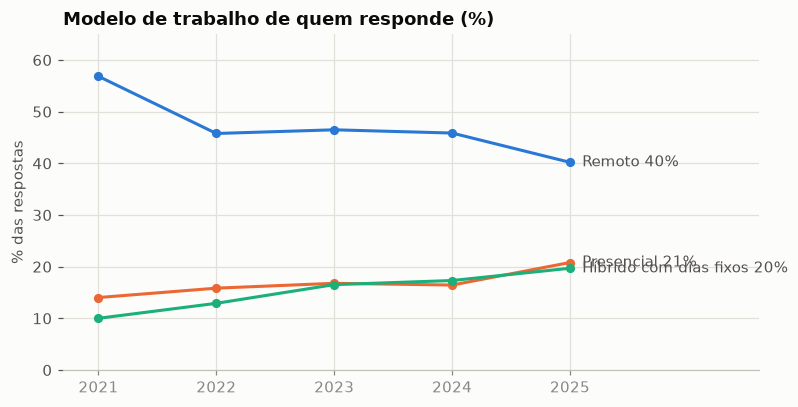

In [7]:
modelo = pd.crosstab(no_brasil["ano"], no_brasil["modelo"], normalize="index").mul(100)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
cores = {"Remoto": AZUL, "Presencial": LARANJA, "Híbrido com dias fixos": VERDE}
for m, cor in cores.items():
    ax.plot(modelo.index, modelo[m], color=cor, marker="o", markersize=5)
    ax.annotate(f"{m} {modelo[m].iloc[-1]:.0f}%", (modelo.index[-1], modelo[m].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", color=TINTA_2)
ax.set_title("Modelo de trabalho de quem responde (%)")
ax.set_xticks(modelo.index)
ax.set_ylim(0, 65)
ax.set_xlim(modelo.index[0] - 0.3, modelo.index[-1] + 1.6)
ax.set_ylabel("% das respostas")
plt.tight_layout()
modelo.round(1)

O 100% remoto caiu de 56,8% (2021) para 40,2% (2025), e o presencial subiu
de 14,0% para 20,8%. O híbrido flexível ficou estável em torno de 20%. Se o
remoto paga mais ou menos com tudo mais igual é uma das perguntas do
caderno de fatores.